In [8]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
import time
import matplotlib.pyplot as plt

# 1. Load the email dataset
df_emails = pd.read_csv('/content/emails.csv')
print("Dataset shape:", df_emails.shape)
display(df_emails.head())

# 2. Check column names and handle preprocessing
# Assumes columns are either ('text', 'spam') or ('Email Text', 'Label') depending on exact schema.
# Let's dynamically detect standard column naming.
text_col = 'text' if 'text' in df_emails.columns else df_emails.columns[0]
target_col = 'spam' if 'spam' in df_emails.columns else df_emails.columns[1]

print(f"Using '{text_col}' as features and '{target_col}' as labels.")

# Extract text and targets
X_raw = df_emails[text_col].astype(str).values
y_raw = df_emails[target_col].values

# 3. Feature extraction using TF-IDF Vectorizer
vectorizer = TfidfVectorizer(max_features=1000, stop_words='english')
X_features = vectorizer.fit_transform(X_raw).toarray()

# 4. Split train and test data
X_train_em, X_test_em, y_train_em, y_test_em = train_test_split(
    X_features, y_raw, test_size=0.2, random_state=42, stratify=y_raw
)

Dataset shape: (5728, 2)


,text,spam
0,Subject: naturally irresistible your corporate...,1
1,Subject: the stock trading gunslinger fanny i...,1
2,Subject: unbelievable new homes made easy im ...,1
3,Subject: 4 color printing special request add...,1
4,"Subject: do not have money , get software cds ...",1


Using 'text' as features and 'spam' as labels.


# Part 1: Single-Layer Perceptron from Scratch

First, we will implement a basic single-layer perceptron using NumPy. We will generate a simple linearly separable 2D dataset and train our perceptron to classify it.

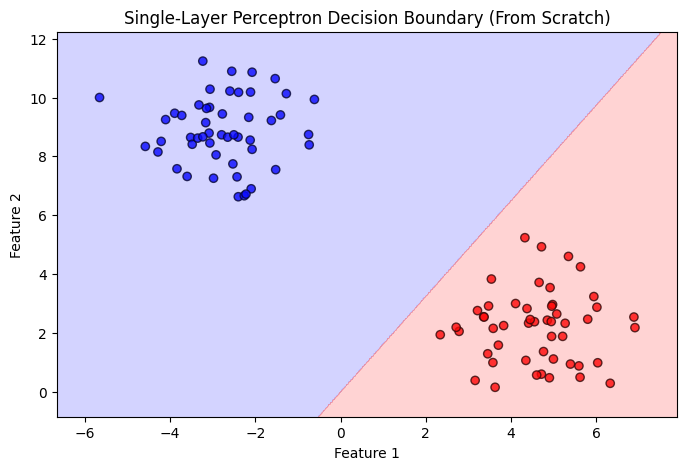

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

# 1. Generate linearly separable data
X, y = make_blobs(n_samples=100, centers=2, n_features=2, random_state=42, cluster_std=1.2)
# Convert targets to 0 and 1
y = (y > 0).astype(int)

# 2. Perceptron Class
class PerceptronFromScratch:
    def __init__(self, learning_rate=0.1, epochs=100):
        self.lr = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = None

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0

        for _ in range(self.epochs):
            for idx, x_i in enumerate(X):
                linear_output = np.dot(x_i, self.weights) + self.bias
                y_predicted = 1 if linear_output >= 0 else 0

                # Perceptron update rule
                update = self.lr * (y[idx] - y_predicted)
                self.weights += update * x_i
                self.bias += update

    def predict(self, X):
        linear_output = np.dot(X, self.weights) + self.bias
        return np.where(linear_output >= 0, 1, 0)

# 3. Train Perceptron
perceptron = PerceptronFromScratch(learning_rate=0.05, epochs=50)
perceptron.fit(X, y)

# 4. Plot Decision Boundary
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='bwr', edgecolors='k', alpha=0.8)

x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
Z = perceptron.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.2, cmap='bwr')
plt.title("Single-Layer Perceptron Decision Boundary (From Scratch)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# Part 2: Multilayer Perceptron (MLP) with Scikit-Learn

Now, we will train a Multilayer Perceptron on a non-linearly separable dataset (the famous moons dataset) and compare the performance when using different activation functions (`identity`, `logistic` (sigmoid), `tanh`, `relu`).

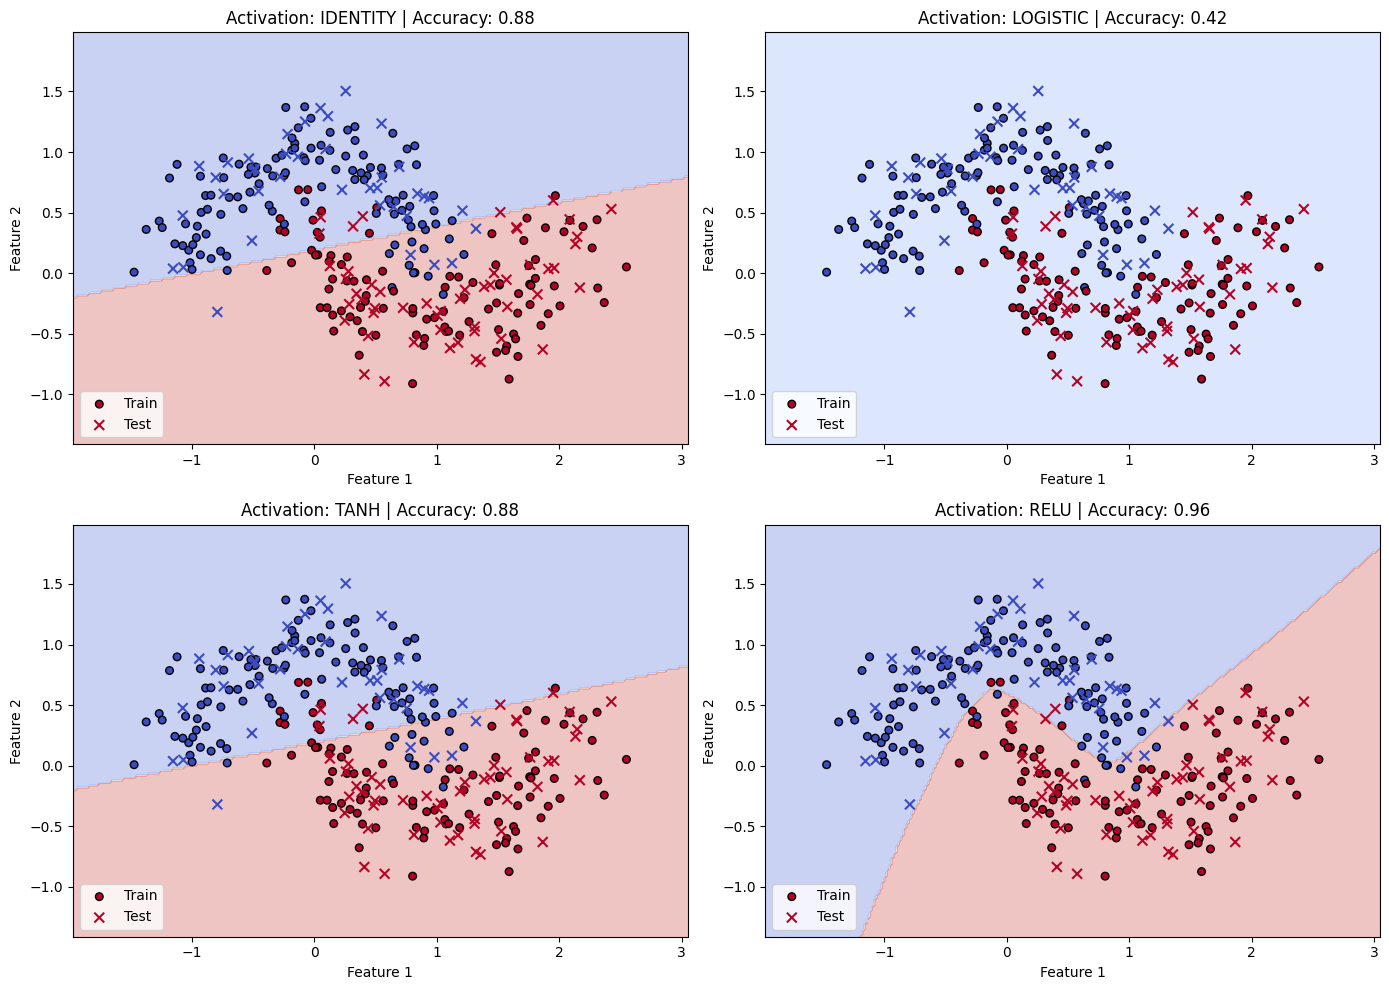

In [2]:
from sklearn.datasets import make_moons
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# 1. Generate non-linearly separable moon dataset
X_moons, y_moons = make_moons(n_samples=300, noise=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X_moons, y_moons, test_size=0.3, random_state=42)

# Define the activation functions to compare
activations = ['identity', 'logistic', 'tanh', 'relu']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for idx, act in enumerate(activations):
    # Initialize and train MLP with current activation function
    mlp = MLPClassifier(hidden_layer_sizes=(100, 50), activation=act, max_iter=1000, random_state=42)
    mlp.fit(X_train, y_train)

    # Evaluate performance
    y_pred = mlp.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    # Visualizing decision boundary
    x_min, x_max = X_moons[:, 0].min() - 0.5, X_moons[:, 0].max() + 0.5
    y_min, y_max = X_moons[:, 1].min() - 0.5, X_moons[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
    Z = mlp.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax = axes[idx]
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', edgecolors='k', s=30, label='Train')
    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='coolwarm', marker='x', s=50, label='Test')
    ax.set_title(f"Activation: {act.upper()} | Accuracy: {acc:.2f}")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.legend(loc='lower left')

plt.tight_layout()
plt.show()

# Part 3: Analyzing the Impact of Hidden Layer Sizes

The capacity of an MLP is determined by its architecture (the number of hidden layers and the number of neurons per layer). Let's train several models with different hidden layer sizes using the ReLU activation function to see how it affects performance and decision boundaries.

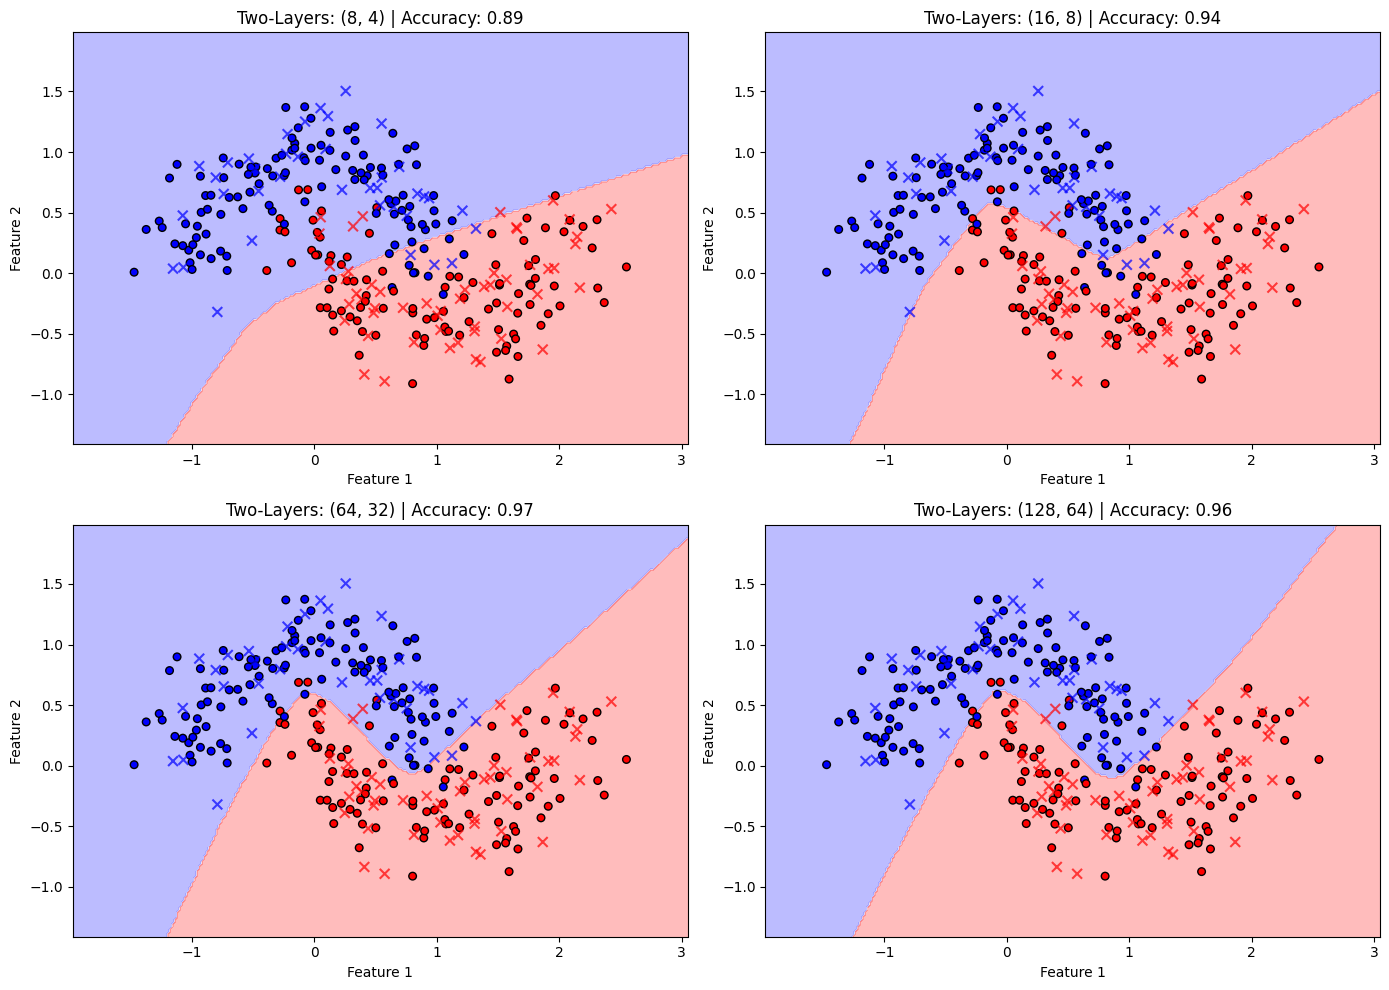

In [4]:
# Define configurations experimenting with two hidden layers of varying capacities
layer_sizes = [
    (8, 4),        # Very small two-layer network
    (16, 8),       # Small two-layer network
    (64, 32),      # Medium two-layer network
    (128, 64)      # Large two-layer network
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for idx, size in enumerate(layer_sizes):
    # Initialize and train MLP
    mlp = MLPClassifier(hidden_layer_sizes=size, activation='relu', max_iter=1500, random_state=42)
    mlp.fit(X_train, y_train)

    # Evaluate performance
    y_pred = mlp.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    # Visualizing decision boundary
    x_min, x_max = X_moons[:, 0].min() - 0.5, X_moons[:, 0].max() + 0.5
    y_min, y_max = X_moons[:, 1].min() - 0.5, X_moons[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
    Z = mlp.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    ax = axes[idx]
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='bwr')
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='bwr', edgecolors='k', s=30)
    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='bwr', marker='x', s=50, alpha=0.7)
    ax.set_title(f"Two-Layers: {size} | Accuracy: {acc:.2f}")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

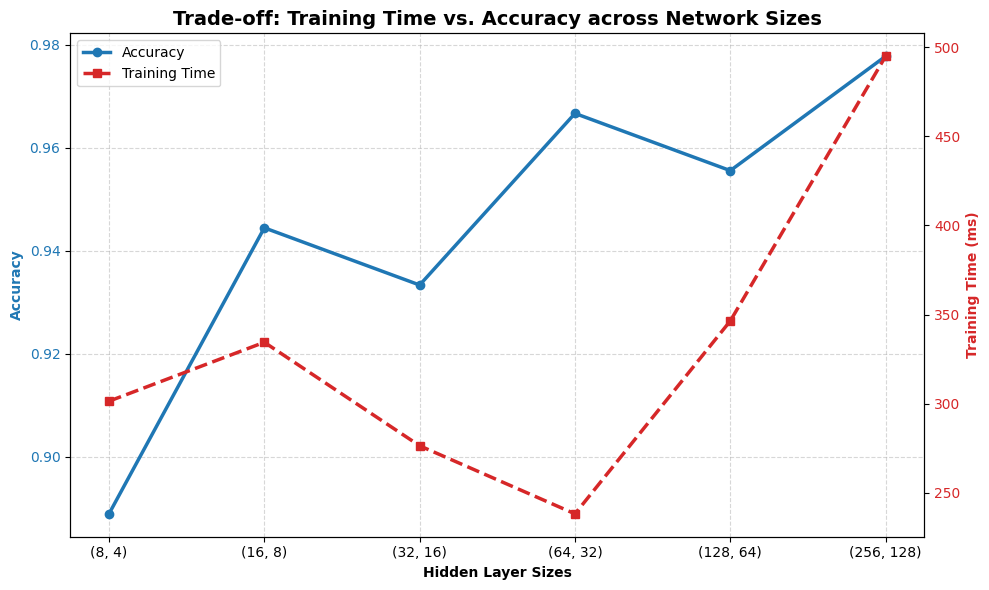

In [5]:
import time

# Define a list of architectures to evaluate
architectures = [
    (8, 4),
    (16, 8),
    (32, 16),
    (64, 32),
    (128, 64),
    (256, 128)
]

training_times = []
accuracies = []

for size in architectures:
    # Measure the training time
    start_time = time.time()
    mlp = MLPClassifier(hidden_layer_sizes=size, activation='relu', max_iter=2000, random_state=42)
    mlp.fit(X_train, y_train)
    end_time = time.time()

    elapsed_time = (end_time - start_time) * 1000 # Convert to milliseconds
    training_times.append(elapsed_time)

    # Calculate accuracy
    y_pred = mlp.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)

# Create a plot with dual y-axes to compare time and accuracy
fig, ax1 = plt.subplots(figsize=(10, 6))

x_labels = [str(size) for size in architectures]

# Plot accuracy on the first y-axis
color = 'tab:blue'
ax1.set_xlabel('Hidden Layer Sizes', fontweight='bold')
ax1.set_ylabel('Accuracy', color=color, fontweight='bold')
line1 = ax1.plot(x_labels, accuracies, marker='o', color=color, linewidth=2.5, label='Accuracy')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

# Plot training time on the second y-axis
ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Training Time (ms)', color=color, fontweight='bold')
line2 = ax2.plot(x_labels, training_times, marker='s', color=color, linestyle='--', linewidth=2.5, label='Training Time')
ax2.tick_params(axis='y', labelcolor=color)

# Title and legend
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

plt.title('Trade-off: Training Time vs. Accuracy across Network Sizes', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Part 4: Spam Classification using the Emails Dataset

We will now load `/content/emails.csv`, inspect its structure, preprocess the text data into numerical features using TF-IDF, and apply our neural network concepts (Single-Layer Perceptron and Multilayer Perceptron architectures) to classify emails as spam or ham.

### Evaluating Architectures on the Emails Dataset

Now, we train and evaluate different MLP configurations on the extracted email features to observe training times and accuracies.

Training MLP with architecture: (16,)...
Accuracy: 0.9869 | Time: 2313.61 ms

Training MLP with architecture: (64,)...
Accuracy: 0.9869 | Time: 5142.87 ms

Training MLP with architecture: (32, 16)...
Accuracy: 0.9869 | Time: 2339.37 ms

Training MLP with architecture: (128, 64)...
Accuracy: 0.9860 | Time: 4658.63 ms



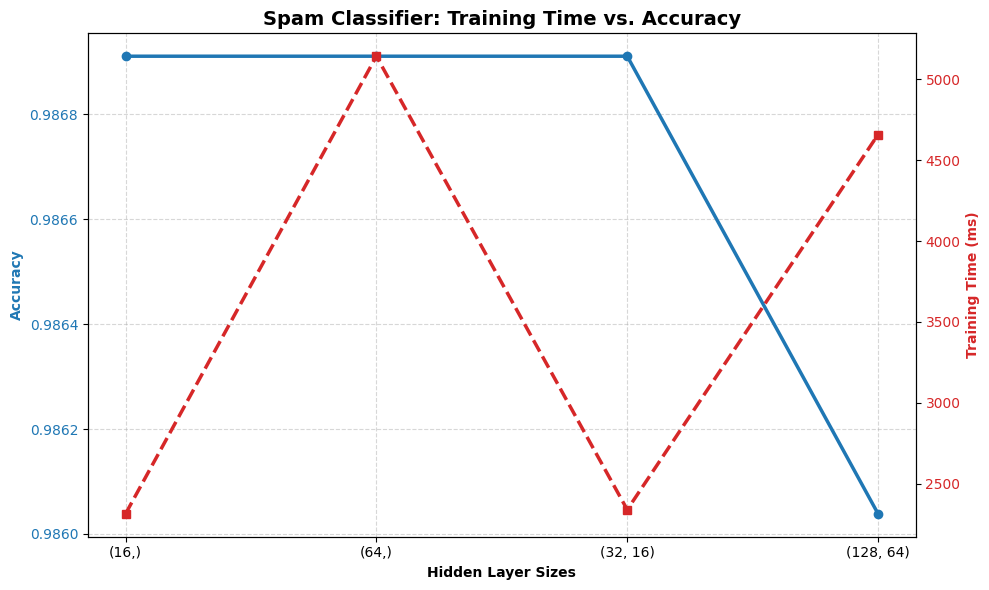

In [7]:
from sklearn.neural_network import MLPClassifier

architectures = [
    (16,),
    (64,),
    (32, 16),
    (128, 64)
]

email_times = []
email_accuracies = []

for size in architectures:
    print(f"Training MLP with architecture: {size}...")
    start = time.time()
    mlp = MLPClassifier(hidden_layer_sizes=size, activation='relu', max_iter=200, random_state=42)
    mlp.fit(X_train_em, y_train_em)
    elapsed = (time.time() - start) * 1000

    y_pred = mlp.predict(X_test_em)
    acc = accuracy_score(y_test_em, y_pred)

    email_times.append(elapsed)
    email_accuracies.append(acc)
    print(f"Accuracy: {acc:.4f} | Time: {elapsed:.2f} ms\n")

# Plot performance metrics for the email dataset
fig, ax1 = plt.subplots(figsize=(10, 6))
x_labels = [str(size) for size in architectures]

color = 'tab:blue'
ax1.set_xlabel('Hidden Layer Sizes', fontweight='bold')
ax1.set_ylabel('Accuracy', color=color, fontweight='bold')
ax1.plot(x_labels, email_accuracies, marker='o', color=color, linewidth=2.5, label='Accuracy')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Training Time (ms)', color=color, fontweight='bold')
ax2.plot(x_labels, email_times, marker='s', color=color, linestyle='--', linewidth=2.5, label='Training Time')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Spam Classifier: Training Time vs. Accuracy', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()